## Introduction

glassnode에서 제공되는 일별 온체인 데이터와  
비트코인 수익률간의 lead-lag relationship을 찾아본다.  

## Import Module

In [2]:
import os
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from util import research as rs

from typing import Dict, Any, List
import logging

from sklearn.preprocessing import StandardScaler
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)
logger = logging.getLogger(__name__)

In [281]:
class DataLoader():
    def __init__(self, config: Dict[str, Any] = None):
        """
        파일 경로로부터 데이터를 로드하고 전처리를 수행하는 클래스
        """
        self.btc_metrics = None
        self.eth_metrics = None
        self.btc_price = None
        self.eth_price = None
        
        # Default configuration
        self.config = {
            'lag_periods': [1, 3, 5, 20],
            'num_samples': 5,
            'noise_std': 0.01,
            'significance_threshold': 0.05,
            'outlier_std': 3,
            'min_causal_strength': 0.1,
            'btc_onchain_path': "C:/Users/wklee/Desktop/WKLee/FBA/Capstone/fba-capstone/glassnode/glassnode_BTC_tier1.csv",
            'eth_onchain_path': "C:/Users/wklee/Desktop/WKLee/FBA/Capstone/fba-capstone/glassnode/glassnode_ETH_tier1.csv",
            'btc_price_path': "C:/Users/wklee/Desktop/WKLee/FBA/Capstone/fba-capstone/binance_1d_BTCUSDT.csv",
            'eth_price_path': "C:/Users/wklee/Desktop/WKLee/FBA/Capstone/fba-capstone/binance_1d_ETHUSDT.csv"
        }
        
        # Update configuration if provided
        if config:
            self.config.update(config)
        
        self.load_data(
            btc_onchain_path= self.config['btc_onchain_path'],
            eth_onchain_path= self.config['eth_onchain_path'],
            btc_price_path= self.config['btc_price_path'],
            eth_price_path= self.config['eth_price_path']
        )
        data = self.prepare_features()
        # 데이터를 시간 순서대로 train/test 분할 (70:30)
        split_idx = int(len(data) * 0.7)
        
        # train set (앞 70%)
        self.data = data[:split_idx].copy()
        
        # test set (뒤 30%) 
        self.data_test = data[split_idx:].copy()
        
        logger.info(f"데이터가 train set {len(self.data)}개, test set {len(self.data_test)}개로 분할되었습니다.")
        
    def remove_outliers(self, df: pd.DataFrame, 
                       columns: List[str], 
                       n_std: int = None) -> pd.DataFrame:
        """Remove outliers from specified columns"""
        logger.info("Removing outliers...")
        if n_std is None:
            n_std = self.config['outlier_std']
            
        df_clean = df.copy()
        for col in columns:
            mean = df[col].mean()
            std = df[col].std()
            print(std)
            df_clean = df_clean[abs(df_clean[col] - mean) <= (n_std * std)]

        return df_clean
    
    def load_data(self, 
                btc_onchain_path: str,
                eth_onchain_path: str, 
                btc_price_path: str,
                eth_price_path: str,
                verbose: bool = True) -> None:
        """Load and prepare all datasets"""
        try:
            print("Loading data files...")
            
            # Load onchain metrics
            self.btc_metrics = pd.read_csv(btc_onchain_path)[['timestamp', 'active_count', 'block_count', 'block_height', 'block_interval_mean', 'block_interval_median', 'receiving_count', 'sending_count', 'sopr']]
            self.eth_metrics = pd.read_csv(eth_onchain_path)[['timestamp', 'active_count', 'block_count', 'block_height', 'block_interval_mean', 'block_interval_median', 'receiving_count', 'sending_count', 'sopr']]
            
            # Load price data
            self.btc_price = pd.read_csv(btc_price_path)
            self.eth_price = pd.read_csv(eth_price_path)

            # Data cleaning - remove pi_cycle_top
            for df in [self.btc_metrics, self.eth_metrics]:
                if 'pi_cycle_top' in df.columns:
                    df.drop('pi_cycle_top', axis=1, inplace=True)   
                if 'close' in df.columns:
                    df.drop('close', axis=1, inplace=True)       
                if 'price_usd_close' in df.columns:
                    df.drop('price_usd_close', axis=1, inplace=True)       
                if 'marketcap_usd' in df.columns:
                    df.drop('marketcap_usd', axis=1, inplace=True)  
                if 'difficulty_latest' in df.columns:
                    df.drop('difficulty_latest', axis=1, inplace=True)
                if 'hash_rate_mean' in df.columns:
                    df.drop('hash_rate_mean', axis=1, inplace=True)
                if 'staking_validators_count' in df.columns:
                    df.drop('staking_validators_count', axis=1, inplace=True)
                if 'staking_phase_0_goal_percent' in df.columns:
                    df.drop('staking_phase_0_goal_percent', axis=1, inplace=True)
                if 'staking_total_validators_count' in df.columns:
                    df.drop('staking_total_validators_count', axis=1, inplace=True)
                    
                         
                df.set_index('timestamp', inplace=True)
                
                for col in df.columns:
                    df[col] = df[col].astype(float)
                
            self.btc_metrics = self.btc_metrics.pct_change().dropna()
            self.eth_metrics = self.eth_metrics.pct_change().dropna()
            
            for col in self.btc_metrics.columns:
                self.btc_metrics[col] = self.btc_metrics[col].astype(float)
                
            for col in self.eth_metrics.columns:
                self.eth_metrics[col] = self.eth_metrics[col].astype(float)
                
            self.btc_metrics.replace([np.inf, -np.inf], np.nan, inplace=True)
            self.eth_metrics.replace([np.inf, -np.inf], np.nan, inplace=True)

            self.btc_price = self.btc_price[['timestamp', 'close']] 
            self.eth_price = self.eth_price[['timestamp', 'close']]
            self.btc_price.set_index('timestamp', inplace=True)
            self.eth_price.set_index('timestamp', inplace=True)
            
            # Set timestamp as index
            for df in [self.btc_metrics, self.eth_metrics, 
                    self.btc_price, self.eth_price]:
                df.sort_index(inplace=True)

            # Calculate returns
            for price_df in [self.btc_price, self.eth_price]:
                price_df['returns'] = np.log(
                    price_df['close'] / price_df['close'].shift(1)
                )
                
            self.btc_price = self.btc_price[['returns']]
            self.eth_price = self.eth_price[['returns']]

            print("Data loading completed successfully")
            
            if verbose:
                # Print data information
                print("\nData shapes after loading:")
                print("BTC metrics shape:", self.btc_metrics.shape)
                print("ETH metrics shape:", self.eth_metrics.shape)
                print("BTC price shape:", self.btc_price.shape)
                print("ETH price shape:", self.eth_price.shape)
                print(self.btc_price.head())
                
                print("\nAvailable BTC metrics:")
                print(self.btc_metrics.columns.tolist())
                print("\nAvailable ETH metrics:")
                print(self.eth_metrics.columns.tolist())
                
                print("\nDate ranges:")
                print("BTC metrics:", self.btc_metrics.index.min(), "to", self.btc_metrics.index.max())
                print("ETH metrics:", self.eth_metrics.index.min(), "to", self.eth_metrics.index.max())
                print("BTC price:", self.btc_price.index.min(), "to", self.btc_price.index.max())
                print("ETH price:", self.eth_price.index.min(), "to", self.eth_price.index.max())
            
        except Exception as e:
            print(f"Error in data loading: {str(e)}")
            raise
            
    def prepare_features(self, normalization: bool = True) -> pd.DataFrame:
        """Prepare features with multiple lags and handle outliers"""
        try:
            logger.info("Preparing features...")
            
            # Copy and clean metrics data
            btc_data = self.btc_metrics.copy()
            eth_data = self.eth_metrics.copy()
            
            # Get column names
            btc_metrics_cols = btc_data.columns
            eth_metrics_cols = eth_data.columns
            
            # # Remove outliers
            # btc_data = self.remove_outliers(btc_data, btc_metrics_cols)
            # eth_data = self.remove_outliers(eth_data, eth_metrics_cols)

            # Normalize metrics
            if normalization:
                btc_data = self.normalize_features(btc_data)
                eth_data = self.normalize_features(eth_data)
            
            # Merge with returns data
            btc_data = self._merge_with_returns(btc_data, self.btc_price, 'btc')
            eth_data = self._merge_with_returns(eth_data, self.eth_price, 'eth')
            
            # Create combined dataset with lagged features
            combined_data = self._create_lagged_features(btc_data, eth_data)
            
            logger.info("Feature preparation completed successfully")
            self._print_feature_info(combined_data)
            
            return combined_data
            
        except Exception as e:
            logger.error(f"Error in feature preparation: {str(e)}")
            raise
            
    def _merge_with_returns(self, metrics_data: pd.DataFrame, 
                        price_data: pd.DataFrame,
                        prefix: str) -> pd.DataFrame:
        """Merge metrics with returns data and add prefixes"""
        # Merge
        merged = metrics_data.merge(
            price_data[['returns']], 
            left_index=True, 
            right_index=True,
            how='inner'
        )
        
        # Add prefixes
        cols_to_prefix = merged.columns.drop('returns').tolist()
        merged = merged.add_prefix(f'{prefix}_')
        merged.rename(columns={f'{prefix}_returns': f'{prefix}_returns'}, 
                    inplace=True)
        
        return merged
        
    def _create_lagged_features(self, btc_data: pd.DataFrame, 
                            eth_data: pd.DataFrame) -> pd.DataFrame:
        """Create lagged features for both cryptocurrencies"""
        # Combine data
        combined_data = btc_data.merge(
            eth_data, 
            left_index=True, 
            right_index=True,
            how='inner'
        )
        
        # Get feature columns
        feature_cols = [col for col in combined_data.columns 
                    if 'returns' not in col]
        returns_cols = ['btc_returns', 'eth_returns']
        
        # Initialize lagged features
        lagged_features = {}
        
        # Create lags
        for col in feature_cols:
            for lag in self.config['lag_periods']:
                lagged_features[f'{col}_lag_{lag}'] = combined_data[col].shift(lag)
        
        # Create final dataset
        lagged_data = pd.DataFrame(lagged_features)
        lagged_data[returns_cols] = combined_data[returns_cols]
        
        # Remove missing values
        lagged_data = lagged_data.dropna()
        
        return lagged_data
        
    def _print_feature_info(self, data: pd.DataFrame):
        """Print information about prepared features"""
        print("\nPrepared dataset info:")
        print("Shape:", data.shape)
        print("Date range:", data.index.min(), "to", data.index.max())
        print("Number of features:", len(data.columns))
        print("Memory usage:", data.memory_usage().sum() / 1024**2, "MB")

    def normalize_features(self, data: pd.DataFrame) -> pd.DataFrame:
        """Normalize features using StandardScaler with error handling"""
        try:
            logger.info("Normalizing features...")
            
            # Select numeric columns
            numeric_data = data.select_dtypes(include=[np.number])
            
            # Normalize
            scaler = StandardScaler()
            normalized_data = pd.DataFrame(
                scaler.fit_transform(numeric_data),
                columns=numeric_data.columns,
                index=numeric_data.index
            )
            
            logger.info("Feature normalization completed")
            return normalized_data
            
        except Exception as e:
            logger.error(f"Error in feature normalization: {str(e)}")
            raise

In [282]:
config = {
    'lag_periods': [0, 1, 3, 5, 10],
    'num_samples': 10,
    'noise_std': 0.01,
    'significance_threshold': 0.05,
    'outlier_std': 3,
    'min_causal_strength': 0.1,
    'btc_onchain_path': "C:/Users/wklee/Desktop/WKLee/FBA/Capstone/fba-capstone/glassnode/glassnode_BTC_tier1.csv",
    'eth_onchain_path': "C:/Users/wklee/Desktop/WKLee/FBA/Capstone/fba-capstone/glassnode/glassnode_ETH_tier1.csv",
    'btc_price_path': "C:/Users/wklee/Desktop/WKLee/FBA/Capstone/fba-capstone/binance_1d_BTCUSDT.csv",
    'eth_price_path': "C:/Users/wklee/Desktop/WKLee/FBA/Capstone/fba-capstone/binance_1d_ETHUSDT.csv"
}

dataloader = DataLoader(config)

2024-11-12 16:36:26,683 - INFO - Preparing features...
2024-11-12 16:36:26,684 - INFO - Normalizing features...
2024-11-12 16:36:26,690 - INFO - Feature normalization completed
2024-11-12 16:36:26,691 - INFO - Normalizing features...
2024-11-12 16:36:26,694 - INFO - Feature normalization completed
2024-11-12 16:36:26,711 - INFO - Feature preparation completed successfully
2024-11-12 16:36:26,718 - INFO - 데이터가 train set 1207개, test set 518개로 분할되었습니다.


Loading data files...
Data loading completed successfully

Data shapes after loading:
BTC metrics shape: (1735, 8)
ETH metrics shape: (1735, 8)
BTC price shape: (1777, 1)
ETH price shape: (1777, 1)
             returns
timestamp           
2020-01-01       NaN
2020-01-02 -0.033200
2020-01-03  0.053015
2020-01-04  0.001245
2020-01-05  0.000631

Available BTC metrics:
['active_count', 'block_count', 'block_height', 'block_interval_mean', 'block_interval_median', 'receiving_count', 'sending_count', 'sopr']

Available ETH metrics:
['active_count', 'block_count', 'block_height', 'block_interval_mean', 'block_interval_median', 'receiving_count', 'sending_count', 'sopr']

Date ranges:
BTC metrics: 2020-01-02 to 2024-10-01
ETH metrics: 2020-01-02 to 2024-10-01
BTC price: 2020-01-01 to 2024-11-11
ETH price: 2020-01-01 to 2024-11-11

Prepared dataset info:
Shape: (1725, 82)
Date range: 2020-01-12 to 2024-10-01
Number of features: 82
Memory usage: 1.0923385620117188 MB


## Analysis

시계열 데이터의 정상성 확보를 위해  
로그변환 및 차분을 실행한다.
이미 ratio의 값이 경우 차분만 실행한다.  

또한 음수의 값을 가지는 'price_drawdown_relative'의 경우 (-1)을 곱해 양수로 이용한다.  

강건성을 위해, train/test 셋을 나누어 진행 

In [7]:
eth_temp = eth_df.copy()

rel_change_col = ["price_drawdown_relative",]
pct_change_col = ["rate", "staking_phase_0_goal_percent",]
nominal_col = eth_temp.columns[~eth_temp.columns.isin(rel_change_col + pct_change_col)]

eth_temp['price_drawdown_relative'] = eth_temp['price_drawdown_relative'] * (-1)
eth_temp[rel_change_col] = eth_temp[rel_change_col].diff(1)
eth_temp[pct_change_col] = (eth_temp[pct_change_col]/100).diff(1)

eth_temp[nominal_col] = np.log(eth_temp[nominal_col]/eth_temp[nominal_col].shift(1))
full_eth = eth_temp.loc[:, ~eth_temp.iloc[1:].isna().any(axis=0)].copy()
full_eth = full_eth.iloc[1:]

btc_temp = btc_df.copy()
btc_temp = btc_temp.astype(float)

rel_change_col = ["price_drawdown_relative",]
pct_change_col = ["rate",]
nominal_col = btc_temp.columns[~btc_temp.columns.isin(rel_change_col + pct_change_col)]
nominal_col = btc_temp.columns

btc_temp['price_drawdown_relative'] = btc_temp['price_drawdown_relative'] * (-1)
btc_temp[rel_change_col] = btc_temp[rel_change_col].diff(1)
btc_temp[pct_change_col] = (btc_temp[pct_change_col]/100).diff(1)

btc_temp[nominal_col] = np.log(btc_temp[nominal_col]/btc_temp[nominal_col].shift(1))
full_btc = btc_temp.loc[:, ~btc_temp.iloc[1:].isna().any(axis=0)].copy()
full_btc = full_btc.iloc[1:]

In [9]:
def split_train_test(df, train_ratio=0.7):
    if len(df) < 10:
        raise ValueError("Too small dataframe (<10)")
    
    train_max = round(len(df) * train_ratio)
    return df.iloc[:train_max, :], df.iloc[train_max:, :]

train_btc, test_btc = split_train_test(full_btc)
train_eth, test_eth = split_train_test(full_eth)

### Using Granger Causality

In [283]:
from statsmodels.tsa.stattools import grangercausalitytests

def test_granger(dataloader: DataLoader,
                 lag_list: list = [1, 3, 5, 10],
                 target: str = 'btc'):
    
    data = dataloader.data.copy()
    onchain_cols = data.columns[data.columns.str.contains("_lag_")]
    onchain_cols = list(set([col.split("_lag_")[0] for col in onchain_cols]))
    target = f"{target}_returns"
    
    significant_results = []
    
    for onchain_col in onchain_cols:
        for maxlag in lag_list:
            result = grangercausalitytests(data[[target, onchain_col + "_lag_0"]], maxlag=maxlag)
            
            for lag in range(1, maxlag+1):
                p_value = result[lag][0]['ssr_chi2test'][1]
                
                if p_value < 0.05:
                    # 계수 추출
                    coef = result[lag][1][1].params[-1] 
                    
                    significant_results.append({
                        'variable': onchain_col,
                        'model_lag': maxlag,
                        'lag': lag,
                        'p_value': p_value,
                        'test_statistic': result[lag][0]['ssr_chi2test'][0],
                        'coefficient': coef
                    })
                
    # 결과를 DataFrame으로 변환하여 반환
    if significant_results:
        return pd.DataFrame(significant_results).sort_values('p_value')
    else:
        return pd.DataFrame(columns=['variable', 'lag', 'p_value', 'test_statistic', 'coefficient'])

granger_btc = test_granger(dataloader, target='btc')
granger_eth = test_granger(dataloader, target='eth')


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=0.3159  , p=0.5742  , df_denom=1203, df_num=1
ssr based chi2 test:   chi2=0.3167  , p=0.5736  , df=1
likelihood ratio test: chi2=0.3167  , p=0.5736  , df=1
parameter F test:         F=0.3159  , p=0.5742  , df_denom=1203, df_num=1

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=0.3159  , p=0.5742  , df_denom=1203, df_num=1
ssr based chi2 test:   chi2=0.3167  , p=0.5736  , df=1
likelihood ratio test: chi2=0.3167  , p=0.5736  , df=1
parameter F test:         F=0.3159  , p=0.5742  , df_denom=1203, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=0.2074  , p=0.8127  , df_denom=1200, df_num=2
ssr based chi2 test:   chi2=0.4165  , p=0.8120  , df=2
likelihood ratio test: chi2=0.4164  , p=0.8120  , df=2
parameter F test:         F=0.2074  , p=0.8127  , df_denom=1200, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=0.2654  , p=0.

### Using VAR Model

In [284]:
from statsmodels.tsa.api import VAR

def test_var(dataloader: DataLoader, 
             lag_list: list = [1, 3, 5, 10],
             target='btc'):
    
    data = dataloader.data.copy()
    onchain_cols = data.columns[data.columns.str.contains("_lag_")]
    onchain_cols = list(set([col.split("_lag_")[0] for col in onchain_cols]))
    target = f"{target}_returns"
    
    var_results = []
    for onchain_col in onchain_cols:
        for maxlag in lag_list:
            # VAR 모델 피팅
            model = VAR(data[[target, onchain_col + "_lag_0"]])
            fitted_model = model.fit(maxlags=maxlag)

            # for i in range(2, len(fitted_model.pvalues), 2):    
            i = len(fitted_model.pvalues) - 1
            if fitted_model.pvalues[target].iloc[i].min() < 0.01:
                result = {
                    'variable': onchain_col,
                    'var_lag': maxlag,
                    'significant_lag': i//2,
                    'coefficient': fitted_model.coefs[i//2-1][0][1],
                    'p_value': fitted_model.pvalues[target].iloc[i].min(),
                    'aic': fitted_model.aic
                }
                var_results.append(result)
    
    return pd.DataFrame(var_results)

var_btc = test_var(dataloader, target='btc')
var_eth = test_var(dataloader, target='eth')

c:\Users\wklee\Desktop\WKLee\FBA\Capstone\fba-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\wklee\Desktop\WKLee\FBA\Capstone\fba-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\wklee\Desktop\WKLee\FBA\Capstone\fba-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\wklee\Desktop\WKLee\FBA\Capstone\fba-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\wklee\Desktop\WKLee\FBA\Cap

### Causal AI

In [252]:
import networkx as nx
from datetime import datetime
from typing import List, Dict, Any, Tuple
from scipy import stats
import json
import logging
import traceback


class CausalAI:
    def __init__(self,
                 dataloader: DataLoader,):
        """Initialize the analysis class with configuration"""
        self.dataloader = dataloader
        self.config = dataloader.config
        
        
    def _calculate_bic_score(self, data: pd.DataFrame, graph: nx.DiGraph) -> float:
        """Calculate BIC score for a graph with robust error handling"""
        try:
            n_samples = len(data)
            if n_samples == 0:
                raise ValueError("Empty dataset")
                
            n_edges = len(graph.edges())
            log_likelihood = 0
            
            for node in graph.nodes():
                parents = list(graph.predecessors(node))
                if parents:
                    # Multiple regression
                    log_likelihood += self._calculate_node_likelihood(
                        data, node, parents, n_samples)
                else:
                    # Just variance
                    variance = np.var(data[node])
                    if variance <= 0:
                        return -np.inf
                    log_likelihood += -0.5 * n_samples * np.log(2 * np.pi * variance) - \
                                    0.5 * n_samples
            
            # Calculate BIC score
            bic_score = log_likelihood - 0.5 * n_edges * np.log(n_samples)
                
            return bic_score
            
        except Exception as e:
            logger.error(f"Error in BIC score calculation: {str(e)}")
            return -np.inf

    def _calculate_node_likelihood(self, data: pd.DataFrame, 
                                 node: str, 
                                 parents: List[str], 
                                 n_samples: int) -> float:
        """Calculate log likelihood for a single node"""
        try:
            X = data[parents]
            y = data[node]
            
            # Add constant term
            X = np.column_stack([np.ones(len(X)), X])
            
            # Calculate coefficients using robust method
            try:
                beta = np.linalg.solve(X.T @ X + np.eye(X.shape[1]) * 1e-6, X.T @ y)
                residuals = y - X @ beta
                variance = np.var(residuals)
                
                if variance <= 0:
                    return -np.inf
                    
                return -0.5 * n_samples * np.log(2 * np.pi * variance) - \
                       0.5 * sum(residuals ** 2) / variance
                       
            except np.linalg.LinAlgError:
                return -np.inf
                
        except Exception as e:
            logger.warning(f"Error in node likelihood calculation: {str(e)}")
            return -np.inf

    def generate_causal_graph(self, data: pd.DataFrame, 
                            num_samples: int = None) -> List[nx.DiGraph]:
        """여러 번의 구조 학습을 통한 인과 그래프 생성"""
        # _generate_single_graph_with_bic 함수는 bic 값이 -inf가 아니면 무조건 그래프를 추가함.  
        # 이 또한 수정 필요 ( BIC 값이 높은애들을 추가하는 방식으로 이루어져야 하는데 BIC와 관계 없이 추가됨. )
        # _generate_single_graph_with_bic -> _apply_fges 함수로 수정 필요.
        try:
            if num_samples is None:
                num_samples = self.config['num_samples']
                
            logger.info(f"Generating {num_samples} causal graphs...")
            
            all_edges = []
            
            # 데이터 전처리는 이미 수행되어 있음
            processed_data = data
            
            for i in range(num_samples):
                # 데이터 부트스트래핑
                sample_indices = np.random.choice(
                    len(processed_data), 
                    size=len(processed_data), 
                    replace=True
                )
                sample_data = processed_data.iloc[sample_indices]
                
                # 단일 그래프 생성
                # graph = self._generate_single_graph_with_bic(sample_data)
                graph = self._generate_single_graph(sample_data, 0.01)
                all_edges.extend(graph.edges())
            
            # 엣지 빈도 계산
            edge_counts = {}
            for edge in all_edges:
                edge_counts[edge] = edge_counts.get(edge, 0) + 1
            
            # 빈도 기반 필터링
            threshold = num_samples * 0.2
            significant_edges = [
                edge for edge, count in edge_counts.items() 
                if count >= threshold
            ]
            
            # 최종 그래프 생성
            final_graphs = []
            final_graph = nx.DiGraph()
            final_graph.add_edges_from(significant_edges)
            final_graphs.append(final_graph)
            
            logger.info(
                f"Found {len(significant_edges)} significant causal relationships"
            )
            self._print_edge_frequencies(edge_counts, num_samples)
            
            return final_graphs
            
        except Exception as e:
            logger.error(f"Error in causal graph generation: {str(e)}")
            raise

    def _print_edge_frequencies(self, edge_counts: Dict, num_samples: int):
        """엣지 빈도 정보 출력"""
        print("\nEdge Frequencies:")
        for edge, count in edge_counts.items():
            print(f"{edge[0]} -> {edge[1]}: {count}/{num_samples} "
                f"({count/num_samples*100:.1f}%)")

    def _generate_single_graph(self, data: pd.DataFrame, 
                             noise_std: float) -> nx.DiGraph:
        """Generate a single causal graph with noise"""
        noise = np.random.normal(0, noise_std, data.shape)
        noisy_data = data.copy()
        noisy_data.loc[:, :] += noise
        return self._apply_fges(noisy_data)

    def _apply_fges(self, data: pd.DataFrame) -> nx.DiGraph:
        """Apply Fast Greedy Equivalence Search algorithm with improvements"""
        try:
            G = nx.DiGraph()
            G.add_nodes_from(data.columns)
            
            returns_cols = ['btc_returns', 'eth_returns']
            onchain_cols = [col for col in data.columns 
                          if col not in returns_cols and 
                          any(f'{lag}' in col for lag in 
                              map(str, self.config['lag_periods']))]    # 이 부분 수정 필요. f"_lag_" -> f"{lag}" 하든가 그냥 lag 하든가 
            
            # Forward phase with progress tracking
            logger.info("Starting forward phase...")
            G = self._forward_phase(data, G, onchain_cols, returns_cols)
            
            # Backward phase with progress tracking
            logger.info("Starting backward phase...")
            G = self._backward_phase(data, G)
            
            return G
            
        except Exception as e:
            logger.error(f"Error in FGES algorithm: {str(e)}")
            raise

    def _forward_phase(self, data: pd.DataFrame, G: nx.DiGraph, 
                      onchain_cols: List[str], 
                      returns_cols: List[str]) -> nx.DiGraph:
        """Forward phase of FGES algorithm"""
        best_score = self._calculate_bic_score(data, G)
        improved = True
        
        while improved:
            improved = False
            best_new_edge = None
            best_new_score = best_score
            
            # Try adding edges
            for source in onchain_cols:
                for target in returns_cols:
                    if not G.has_edge(source, target):
                        score = self._try_add_edge(data, G, source, 
                                                 target, best_new_score)
                        if score > best_new_score:
                            best_new_score = score
                            best_new_edge = (source, target)
                            improved = True
            
            if improved:
                G.add_edge(*best_new_edge)
                best_score = best_new_score
                logger.info(f"Added edge: {best_new_edge[0]} -> {best_new_edge[1]} "
                          f"(Score: {best_score:.4f})")
                
        return G

    def _backward_phase(self, data: pd.DataFrame, G: nx.DiGraph) -> nx.DiGraph:
        """Backward phase of FGES algorithm"""
        best_score = self._calculate_bic_score(data, G)
        improved = True
        
        while improved:
            improved = False
            best_remove_edge = None
            best_remove_score = best_score
            
            # Try removing edges
            for edge in list(G.edges()):
                score = self._try_remove_edge(data, G, edge, best_remove_score)
                if score > best_remove_score:
                    best_remove_score = score
                    best_remove_edge = edge
                    improved = True
            
            if improved:
                G.remove_edge(*best_remove_edge)
                best_score = best_remove_score
                logger.info(f"Removed edge: {best_remove_edge[0]} -> "
                          f"{best_remove_edge[1]} (Score: {best_score:.4f})")
                
        return G

    def _try_add_edge(self, data: pd.DataFrame, G: nx.DiGraph, 
                      source: str, target: str, 
                      current_best: float) -> float:
        """Try adding an edge and return the score"""
        G_new = G.copy()
        G_new.add_edge(source, target)
        
        if not nx.is_directed_acyclic_graph(G_new):
            return -np.inf
            
        return self._calculate_bic_score(data, G_new)

    def _try_remove_edge(self, data: pd.DataFrame, G: nx.DiGraph, 
                        edge: Tuple[str, str], 
                        current_best: float) -> float:
        """Try removing an edge and return the score"""
        G_new = G.copy()
        G_new.remove_edge(*edge)
        return self._calculate_bic_score(data, G_new)
    

    def calculate_causal_strength(self, graphs: List[nx.DiGraph], 
                            data: pd.DataFrame) -> Dict[str, float]:
        """Calculate causal strength using ATE with improved matching"""
        try:
            logger.info("Calculating causal strengths...")
            causal_strengths = {}
            graph_scores = []
            
            # Calculate BIC scores for all graphs
            for graph in graphs:
                score = self._calculate_bic_score(data, graph)
                graph_scores.append(score)
            
            # Convert scores to weights
            scores_array = np.array(graph_scores)
            max_score = np.max(scores_array)
            weights = np.exp(scores_array - max_score)
            weights = weights / np.sum(weights)
            
            # Process each unique edge
            unique_edges = set([e for g in graphs for e in g.edges()])
            
            for edge in unique_edges:
                source, target = edge
                strengths = []
                edge_weights = []
                
                # Calculate strength for each graph containing the edge
                for graph, weight in zip(graphs, weights):
                    if graph.has_edge(source, target):
                        strength = self._calculate_robust_ate(
                            data=data,
                            source=source,
                            target=target,
                            graph=graph
                        )
                        if strength is not None:
                            strengths.append(strength)
                            edge_weights.append(weight)
                
                if strengths:
                    # Calculate weighted average with normalization
                    edge_weights = np.array(edge_weights)
                    edge_weights = edge_weights / np.sum(edge_weights)
                    causal_strengths[f"{source}->{target}"] = np.average(
                        strengths, 
                        weights=edge_weights
                    )
            
            logger.info(f"Found {len(causal_strengths)} causal relationships")
            return causal_strengths
            
        except Exception as e:
            logger.error(f"Error in causal strength calculation: {str(e)}")
            raise

    def _calculate_robust_ate(self, data: pd.DataFrame, 
                            source: str, target: str, 
                            graph: nx.DiGraph) -> float:
        """Calculate ATE with improved matching and significance testing"""
        try:
            # Get confounders
            confounders = [n for n in graph.nodes() 
                          if n != source and n != target and 
                          (graph.has_edge(n, target) or graph.has_edge(n, source))]
            
            treatment = data[source].values
            outcome = data[target].values
            
            # Calculate propensity scores
            if confounders:
                ps_scores = self._calculate_propensity_scores(
                    data[confounders], treatment)
            else:
                ps_scores = np.ones(len(treatment)) * 0.5
            
            # Match treatment and control groups
            matched_diffs = self._match_and_calculate_effects(
                treatment, outcome, ps_scores)
            
            if not matched_diffs:
                return None
            
            # Calculate ATE
            ate = np.mean(matched_diffs)
            
            # Perform significance test
            if self._is_effect_significant(matched_diffs):
                return ate
            return None
            
        except Exception as e:
            logger.warning(f"Error in ATE calculation: {str(e)}")
            return None

    def _calculate_propensity_scores(self, confounders: pd.DataFrame, 
                                   treatment: np.ndarray) -> np.ndarray:
        """Calculate propensity scores using logistic regression"""
        from sklearn.linear_model import LogisticRegression
        treatment_binary = (treatment > np.median(treatment)).astype(int)
        
        ps_model = LogisticRegression(
            random_state=42, 
            max_iter=1000,
            solver='lbfgs'
        )
        ps_model.fit(confounders, treatment_binary)
        return ps_model.predict_proba(confounders)[:, 1]

    def _match_and_calculate_effects(self, treatment: np.ndarray,
                                   outcome: np.ndarray,
                                   ps_scores: np.ndarray) -> List[float]:
        """Match treatment and control groups using propensity scores"""
        treatment_median = np.median(treatment)
        treated_idx = treatment > treatment_median
        control_idx = ~treated_idx
        
        treated_outcomes = outcome[treated_idx]
        treated_ps = ps_scores[treated_idx]
        control_outcomes = outcome[control_idx]
        control_ps = ps_scores[control_idx]
        
        matched_diffs = []
        
        for t_idx in range(len(treated_outcomes)):
            ps_diff = np.abs(treated_ps[t_idx] - control_ps) # propencity score의 차이가 가장 큰 애들을 추림. 즉 treatment를 받을 확률이 가장 큰 애들만 추린다는 것.
            best_matches = np.argsort(ps_diff)[:3]  # Get top 3 matches # 왜 top 3 만 match 하지? 이러면 ATE가 너무 높아짐.
            
            # Calculate average effect across matches
            effects = [treated_outcomes[t_idx] - control_outcomes[m] 
                      for m in best_matches]
            matched_diffs.append(np.mean(effects))
        
        return matched_diffs

    def _is_effect_significant(self, effects: List[float]) -> bool:
        """Test if treatment effect is statistically significant"""
        _, p_value = stats.ttest_1samp(effects, 0)
        return p_value < self.config['significance_threshold']

    def analyze_returns_causality(self) -> Dict[str, Any]:
        """Analyze causality between onchain metrics and returns"""
        try:
            logger.info("Starting causality analysis...")
            analyze_data = self.dataloader.data.copy()
            analyze_data = analyze_data.loc[:, ~analyze_data.columns.str.contains("_lag_0")]
            
            # Generate causal graphs
            causal_graphs = self.generate_causal_graph(analyze_data)
            
            # Calculate causal strengths
            causal_strengths = self.calculate_causal_strength(
                causal_graphs, analyze_data)
            
            # Organize results
            results = self._organize_results(causal_strengths)
            
            # Save results if needed
            self._save_results(results)
            
            # Create visualizations
            self._create_visualizations(
                causal_graphs, causal_strengths, 
                analyze_data, results
            )
            
            logger.info("Causality analysis completed successfully")
            return results
            
        except Exception as e:
            logger.error(f"Error in causality analysis: {str(e)}")
            raise

    def _organize_results(self, causal_strengths: Dict[str, float]) -> Dict[str, Any]:
        """Organize analysis results by cryptocurrency and lag period"""
        results = {
            'btc_factors': {lag: {} for lag in self.config['lag_periods']},
            'eth_factors': {lag: {} for lag in self.config['lag_periods']},
            'causal_strengths': causal_strengths
        }
        
        # Classify results
        for edge, strength in causal_strengths.items():
            source, target = edge.split('->')
            
            for lag in self.config['lag_periods']:
                if f'_lag_{lag}' in source:
                    if 'btc_returns' in target:
                        results['btc_factors'][lag][edge] = strength
                    elif 'eth_returns' in target:
                        results['eth_factors'][lag][edge] = strength
        
        # Add summary statistics
        results['summary'] = self._calculate_summary_statistics(results)
        
        return results

    def _calculate_summary_statistics(self, results: Dict[str, Any]) -> Dict[str, Any]:
        """Calculate summary statistics for the results"""
        summary = {}
        
        for lag in self.config['lag_periods']:
            btc_factors = results['btc_factors'][lag]
            eth_factors = results['eth_factors'][lag]
            
            btc_count = len(btc_factors)
            eth_count = len(eth_factors)
            
            btc_avg = np.mean([abs(v) for v in btc_factors.values()]) \
                     if btc_count > 0 else 0.0
            eth_avg = np.mean([abs(v) for v in eth_factors.values()]) \
                     if eth_count > 0 else 0.0
            
            summary[lag] = {
                'btc_count': btc_count,
                'btc_avg_strength': btc_avg,
                'eth_count': eth_count,
                'eth_avg_strength': eth_avg
            }
            
        return summary

    def _save_results(self, results: Dict[str, Any]) -> None:
        """Save analysis results to file"""
        try:
            timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
            filename = f'causal_analysis_results_{timestamp}.json'
            
            with open(filename, 'w') as f:
                json.dump(results, f, indent=4)
                
            logger.info(f"Results saved to {filename}")
            
        except Exception as e:
            logger.warning(f"Failed to save results: {str(e)}")

    def _create_visualizations(self, graphs: List[nx.DiGraph],
                             strengths: Dict[str, float],
                             data: pd.DataFrame,
                             results: Dict[str, Any]) -> None:
        """Create all visualizations"""
        try:
            self.visualize_causal_network(graphs, strengths)
            self.plot_causal_strength_heatmap(results)
            self.plot_temporal_evolution(data, results)
            
        except Exception as e:
            logger.warning(f"Error in visualization creation: {str(e)}")


    def run(self):
        # Configuration settings
        config = self.dataloader.config
        results = self.analyze_returns_causality()
        return results 


def print_results(results: Dict[str, Any]):
    """Print formatted analysis results"""
    lag_periods = [1, 3, 5, 10, 20]
    
    # Print Bitcoin results
    print("\nBitcoin Returns Causal Factors:")
    print("=" * 40)
    for lag in lag_periods:
        print(f"\nLag {lag} days:")
        btc_factors = results['btc_factors'][lag]
        if btc_factors:
            # Sort factors by absolute strength
            sorted_factors = sorted(
                btc_factors.items(),
                key=lambda x: abs(x[1]),
                reverse=True
            )
            
            # Print top 10 factors
            for factor, strength in sorted_factors[:10]:
                metric = factor.split('->')[0].rsplit('_lag_', 1)[0]
                print(f"{metric:40s}: {strength:>8.4f}")
        else:
            print("No significant causal factors found")
    
    # Print Ethereum results
    print("\nEthereum Returns Causal Factors:")
    print("=" * 40)
    for lag in lag_periods:
        print(f"\nLag {lag} days:")
        eth_factors = results['eth_factors'][lag]
        if eth_factors:
            # Sort factors by absolute strength
            sorted_factors = sorted(
                eth_factors.items(),
                key=lambda x: abs(x[1]),
                reverse=True
            )
            
            # Print top 10 factors
            for factor, strength in sorted_factors[:10]:
                metric = factor.split('->')[0].rsplit('_lag_', 1)[0]
                print(f"{metric:40s}: {strength:>8.4f}")
        else:
            print("No significant causal factors found")
    
    # Print summary statistics
    print("\nSummary Statistics:")
    print("=" * 40)
    for lag in lag_periods:
        print(f"\nLag {lag} days:")
        summary = results['summary'][lag]
        
        if summary['btc_count'] > 0:
            print(f"BTC metrics found: {summary['btc_count']} "
                  f"(Avg. strength: {summary['btc_avg_strength']:.4f})")
            
            # Additional statistics
            btc_factors = results['btc_factors'][lag]
            if btc_factors:
                strengths = np.array(list(btc_factors.values()))
                print(f"  Max strength: {np.max(np.abs(strengths)):.4f}")
                print(f"  Min strength: {np.min(np.abs(strengths)):.4f}")
                print(f"  Std deviation: {np.std(strengths):.4f}")
        else:
            print("No significant BTC metrics found")
        
        if summary['eth_count'] > 0:
            print(f"ETH metrics found: {summary['eth_count']} "
                  f"(Avg. strength: {summary['eth_avg_strength']:.4f})")
            
            # Additional statistics
            eth_factors = results['eth_factors'][lag]
            if eth_factors:
                strengths = np.array(list(eth_factors.values()))
                print(f"  Max strength: {np.max(np.abs(strengths)):.4f}")
                print(f"  Min strength: {np.min(np.abs(strengths)):.4f}")
                print(f"  Std deviation: {np.std(strengths):.4f}")
        else:
            print("No significant ETH metrics found")

In [253]:
config['num_samples'] = 30
config['lag_periods'] = [0, 1, 3, 5, 10]
config['significance_threshold'] = 0.1
dataloader = DataLoader(config)

analysis = CausalAI(dataloader)
results = analysis.run()

2024-11-12 16:25:48,699 - INFO - Preparing features...
2024-11-12 16:25:48,701 - INFO - Normalizing features...
2024-11-12 16:25:48,704 - INFO - Feature normalization completed
2024-11-12 16:25:48,705 - INFO - Normalizing features...
2024-11-12 16:25:48,709 - INFO - Feature normalization completed
2024-11-12 16:25:48,721 - INFO - Feature preparation completed successfully
2024-11-12 16:25:48,726 - INFO - 데이터가 train set 1207개, test set 518개로 분할되었습니다.
2024-11-12 16:25:48,729 - INFO - Starting causality analysis...
2024-11-12 16:25:48,731 - INFO - Generating 30 causal graphs...
2024-11-12 16:25:48,735 - INFO - Starting forward phase...


Loading data files...
Data loading completed successfully

Data shapes after loading:
BTC metrics shape: (1735, 8)
ETH metrics shape: (1735, 8)
BTC price shape: (1777, 1)
ETH price shape: (1777, 1)
             returns
timestamp           
2020-01-01       NaN
2020-01-02 -0.033200
2020-01-03  0.053015
2020-01-04  0.001245
2020-01-05  0.000631

Available BTC metrics:
['active_count', 'block_count', 'block_height', 'block_interval_mean', 'block_interval_median', 'receiving_count', 'sending_count', 'sopr']

Available ETH metrics:
['active_count', 'block_count', 'block_height', 'block_interval_mean', 'block_interval_median', 'receiving_count', 'sending_count', 'sopr']

Date ranges:
BTC metrics: 2020-01-02 to 2024-10-01
ETH metrics: 2020-01-02 to 2024-10-01
BTC price: 2020-01-01 to 2024-11-11
ETH price: 2020-01-01 to 2024-11-11

Prepared dataset info:
Shape: (1725, 82)
Date range: 2020-01-12 to 2024-10-01
Number of features: 82
Memory usage: 1.0923385620117188 MB


2024-11-12 16:25:49,159 - INFO - Added edge: eth_receiving_count_lag_3 -> eth_returns (Score: -106210.4927)
2024-11-12 16:25:49,597 - INFO - Added edge: eth_block_count_lag_3 -> btc_returns (Score: -106209.1272)
2024-11-12 16:25:50,008 - INFO - Added edge: btc_block_interval_median_lag_10 -> eth_returns (Score: -106208.7110)
2024-11-12 16:25:50,412 - INFO - Added edge: btc_sending_count_lag_10 -> btc_returns (Score: -106208.5394)
2024-11-12 16:25:50,911 - INFO - Starting backward phase...
2024-11-12 16:25:50,932 - INFO - Starting forward phase...
2024-11-12 16:25:51,312 - INFO - Added edge: eth_block_count_lag_3 -> btc_returns (Score: -107516.9115)
2024-11-12 16:25:51,741 - INFO - Added edge: eth_block_count_lag_3 -> eth_returns (Score: -107509.1962)
2024-11-12 16:25:52,212 - INFO - Added edge: btc_block_height_lag_1 -> eth_returns (Score: -107504.8411)
2024-11-12 16:25:52,684 - INFO - Added edge: eth_receiving_count_lag_3 -> eth_returns (Score: -107501.1683)
2024-11-12 16:25:53,123 - 


Edge Frequencies:
btc_block_interval_median_lag_10 -> eth_returns: 8/30 (26.7%)
btc_sending_count_lag_10 -> btc_returns: 5/30 (16.7%)
eth_block_count_lag_3 -> btc_returns: 14/30 (46.7%)
eth_receiving_count_lag_3 -> eth_returns: 13/30 (43.3%)
btc_block_count_lag_1 -> btc_returns: 2/30 (6.7%)
btc_block_height_lag_1 -> eth_returns: 6/30 (20.0%)
btc_block_interval_median_lag_10 -> btc_returns: 5/30 (16.7%)
eth_block_count_lag_3 -> eth_returns: 7/30 (23.3%)
eth_block_interval_median_lag_3 -> eth_returns: 2/30 (6.7%)
eth_block_interval_median_lag_10 -> eth_returns: 6/30 (20.0%)
eth_sending_count_lag_10 -> btc_returns: 2/30 (6.7%)
eth_sending_count_lag_10 -> eth_returns: 2/30 (6.7%)
btc_block_height_lag_5 -> btc_returns: 4/30 (13.3%)
eth_block_height_lag_3 -> btc_returns: 4/30 (13.3%)
btc_block_interval_median_lag_1 -> btc_returns: 1/30 (3.3%)
eth_block_interval_mean_lag_5 -> btc_returns: 1/30 (3.3%)
btc_receiving_count_lag_10 -> btc_returns: 2/30 (6.7%)
eth_sopr_lag_5 -> eth_returns: 1/30 (

2024-11-12 16:27:22,322 - INFO - Results saved to causal_analysis_results_20241112_162722.json
2024-11-12 16:27:22,322 - WARNING - Error in visualization creation: 'CausalAI' object has no attribute 'visualize_causal_network'
2024-11-12 16:27:22,322 - INFO - Causality analysis completed successfully


In [423]:
results

{'btc_factors': {0: {}, 1: {}, 3: {}, 5: {}, 10: {}},
 'eth_factors': {0: {},
  1: {'eth_block_interval_median_lag_10->eth_returns': np.float64(0.008134897350057813),
   'btc_block_height_lag_1->eth_returns': np.float64(0.007345623015456133),
   'btc_block_interval_median_lag_10->eth_returns': np.float64(0.005433988694288758)},
  3: {},
  5: {},
  10: {'eth_block_interval_median_lag_10->eth_returns': np.float64(0.008134897350057813),
   'btc_block_interval_median_lag_10->eth_returns': np.float64(0.005433988694288758)}},
 'causal_strengths': {'eth_block_interval_median_lag_10->eth_returns': np.float64(0.008134897350057813),
  'btc_block_height_lag_1->eth_returns': np.float64(0.007345623015456133),
  'btc_block_interval_median_lag_10->eth_returns': np.float64(0.005433988694288758)},
 'summary': {0: {'btc_count': 0,
   'btc_avg_strength': 0.0,
   'eth_count': 0,
   'eth_avg_strength': 0.0},
  1: {'btc_count': 0,
   'btc_avg_strength': 0.0,
   'eth_count': 3,
   'eth_avg_strength': np.floa

C:\Users\wklee\AppData\Local\Temp\ipykernel_14808\2368890874.py:50: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


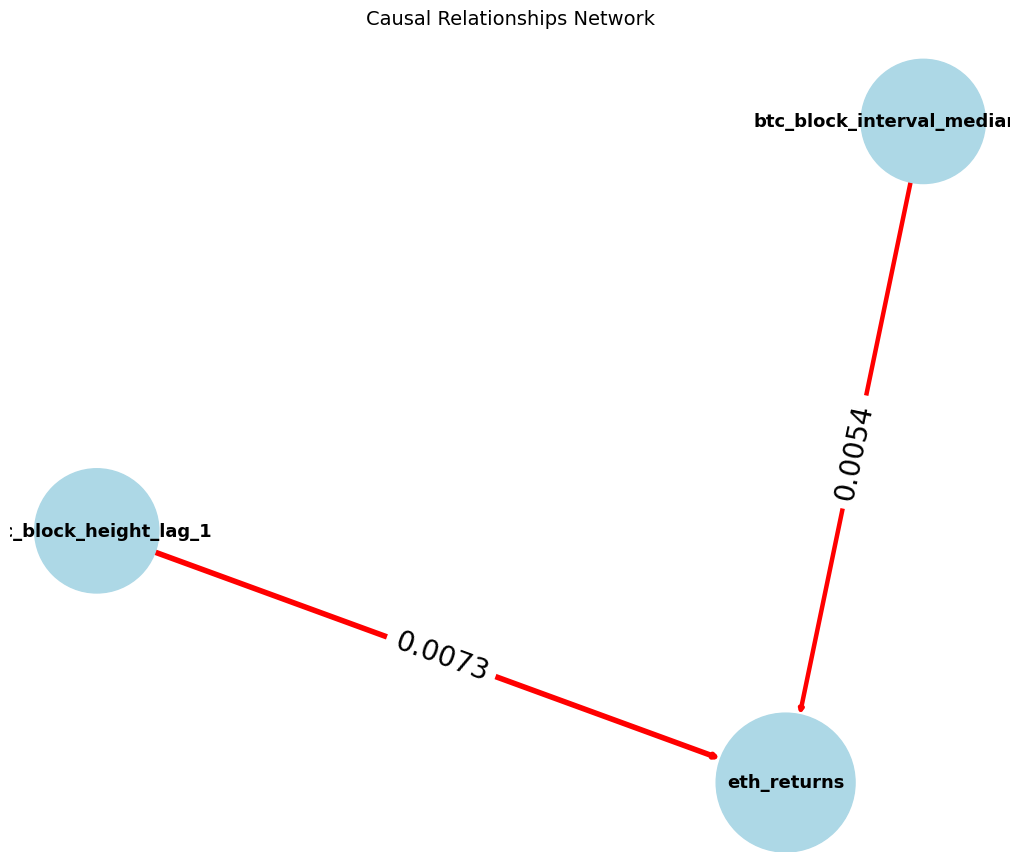

In [360]:
import networkx as nx
import matplotlib.pyplot as plt

# 그래프 생성
G = nx.DiGraph()

# 인과관계 추가 및 절대값 강도 계산
edge_weights = {}
edge_colors = []
for relationship, strength in results['causal_strengths'].items():
    source, target = relationship.split('->')
    if source == 'eth_block_interval_median_lag_10':
        continue
    abs_strength = abs(strength)
    G.add_edge(source, target, weight=strength, abs_weight=abs_strength)
    edge_weights[(source, target)] = abs_strength
    # 양의 강도는 빨간색, 음의 강도는 파란색으로 설정
    edge_colors.append('red' if strength > 0 else 'blue')

# 그래프 레이아웃 설정 - k값을 더욱 줄여서 노드 간 거리를 매우 좁힘
pos = nx.spring_layout(G, k=0.0001) 

# 노드 크기 설정 
node_sizes = []
for node in G.nodes():
    if node == 'eth_returns':
        node_sizes.append(10000)  # eth_returns 노드 크기 증가
    else:
        node_sizes.append(8000)  # 나머지 노드 크기 증가

# 엣지 너비 계산 (절대값 강도에 비례)
max_width = 4  # 최대 너비 증가
min_width = 1  # 최소 너비 증가
widths = [min_width + (max_width-min_width)*w/max(edge_weights.values()) 
          for w in edge_weights.values()]

# 그래프 그리기 - 전체 크기 증가
plt.figure(figsize=(10, 8))
nx.draw(G, pos, with_labels=True, node_color='lightblue',
        node_size=node_sizes, font_size=13, font_weight='bold',  # 노드 글자 크기 증가
        arrows=True, edge_color=edge_colors, width=widths,
        arrowsize=5)  # 화살표 크기 증가

# 엣지 가중치(인과강도) 표시 - 폰트 크기 증가
edge_labels = nx.get_edge_attributes(G, 'weight')
edge_labels = {k: f'{v:.4f}' for k, v in edge_labels.items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=20)  # 엣지 레이블 글자 크기 증가

plt.title('Causal Relationships Network', pad=20, fontsize=14)  # 제목 글자 크기 증가
plt.tight_layout()
plt.show()

In [296]:
# 방법론별, 자산별 유의미한 변수 정리
granger_btc_sig = granger_btc.sort_values(by=['variable', 'p_value']).drop_duplicates(subset=['model_lag', 'variable'], keep='first')
granger_eth_sig = granger_eth.sort_values(by=['variable', 'p_value']).drop_duplicates(subset=['model_lag', 'variable'], keep='first')
var_btc_sig = var_btc.sort_values(by=['variable', 'p_value']).drop_duplicates(subset='variable', keep='first')
# var_eth_sig = var_eth.sort_values(by=['variable', 'p_value']).drop_duplicates(subset='variable', keep='first')

# Granger 인과관계 변수와 계수를 딕셔너리로 저장
significant_vars_granger_btc = {
    row['variable'] + "_lag_" + str(row['model_lag']): row['coefficient'] 
    for _, row in granger_btc_sig.iterrows()
}
significant_vars_granger_eth = {
    row['variable'] + "_lag_" + str(row['model_lag']): row['coefficient']
    for _, row in granger_eth_sig.iterrows()
}

# VAR 모델 변수와 계수를 딕셔너리로 저장
significant_vars_VAR_btc = {
    row['variable'] + "_lag_" + str(row['significant_lag']): row['coefficient']
    for _, row in var_btc_sig.iterrows()
}
significant_vars_VAR_eth = {
    row['variable'] + "_lag_" + str(row['significant_lag']): row['coefficient']
    for _, row in var_eth_sig.iterrows()
}

# 인과추론 변수와 강도를 딕셔너리로 저장
significant_vars_CI_btc = {
    k.split("->")[0]: v 
    for k, v in results['causal_strengths'].items() 
    if "btc" in k.split("->")[1]
}
significant_vars_CI_eth = {
    k.split("->")[0]: v 
    for k, v in results['causal_strengths'].items() 
    if "eth" in k.split("->")[1]
}

KeyError: 'variable'

### Profitability

=== Bitcoin Trading Strategies ===


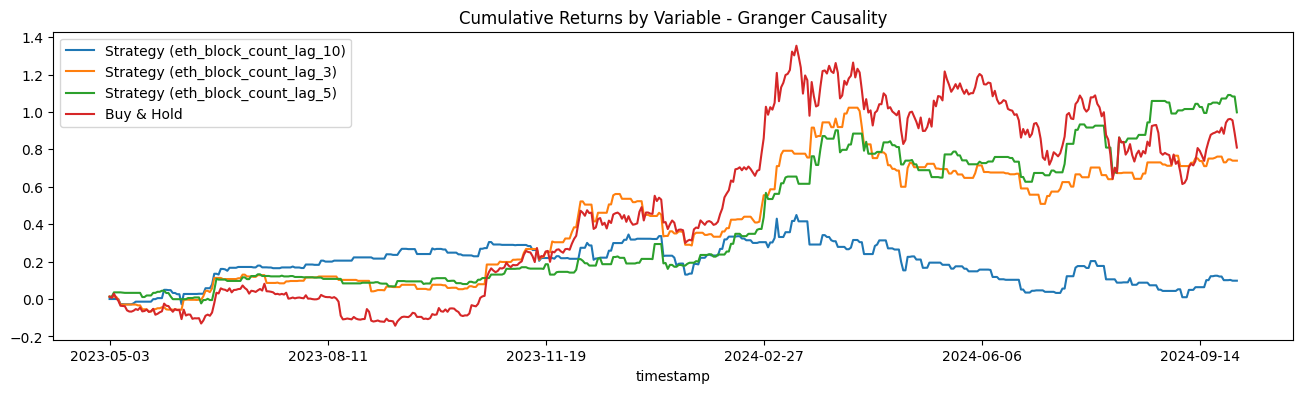


=== Granger Causality Performance by Variable ===

Variable: eth_block_count_lag_10
Annualized Return: 13.65%
Volatility: 39.49%
Sharpe Ratio: 0.35
Maximum Drawdown: -30.33%
Number of Trades: 184
Win Rate: 48.91%

Variable: eth_block_count_lag_3
Annualized Return: 111.73%
Volatility: 40.30%
Sharpe Ratio: 2.77
Maximum Drawdown: -25.42%
Number of Trades: 186
Win Rate: 53.23%

Variable: eth_block_count_lag_5
Annualized Return: 154.15%
Volatility: 41.35%
Sharpe Ratio: 3.73
Maximum Drawdown: -14.46%
Number of Trades: 187
Win Rate: 54.55%
No valid strategies found for VAR Model
No valid strategies found for Causal Inference

=== Ethereum Trading Strategies ===


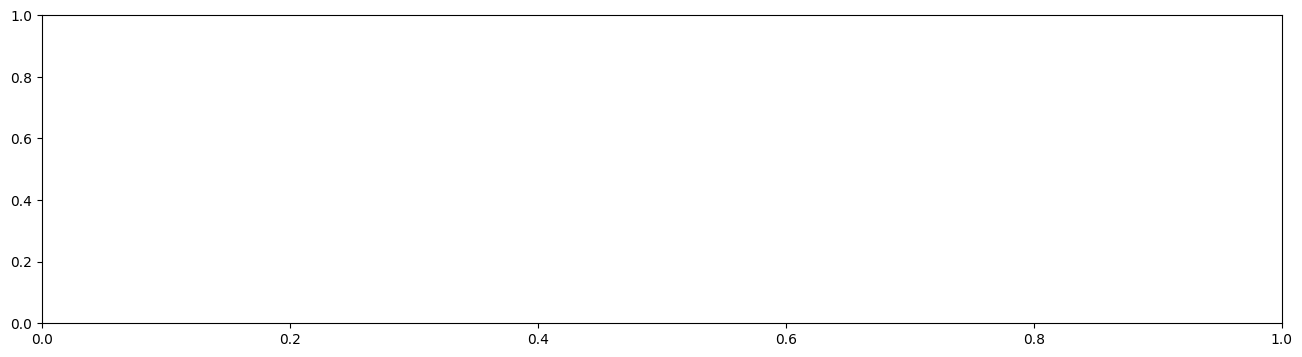

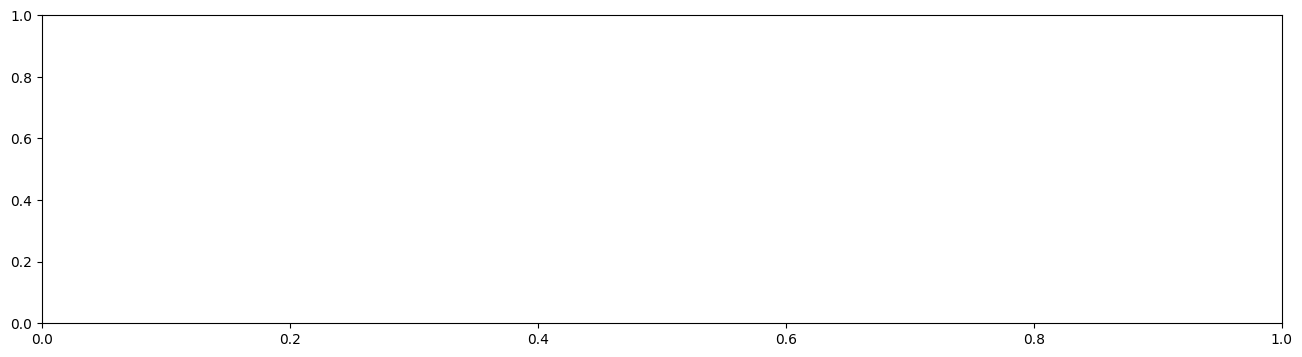

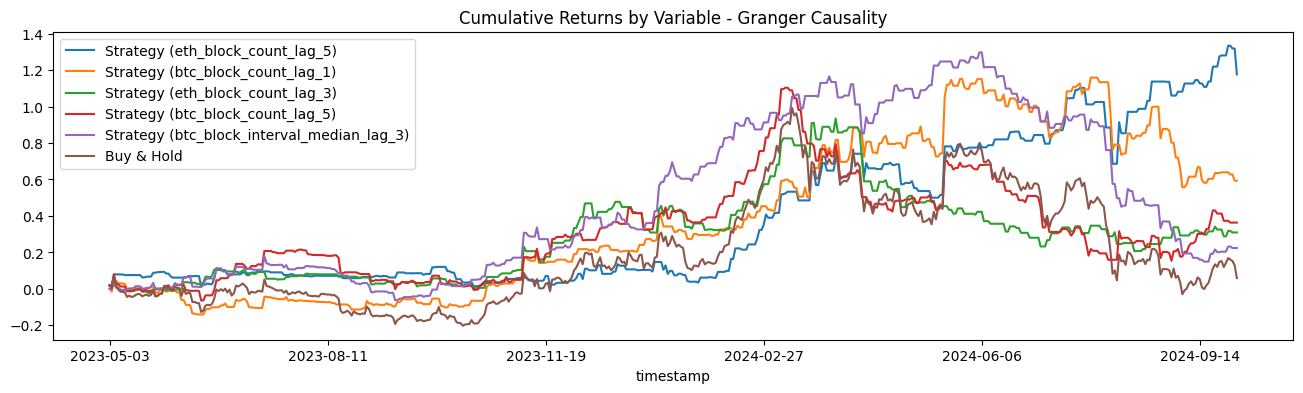


=== Granger Causality Performance by Variable ===

Variable: eth_block_count_lag_5
Annualized Return: 185.20%
Volatility: 50.61%
Sharpe Ratio: 3.66
Maximum Drawdown: -19.80%
Number of Trades: 187
Win Rate: 58.82%

Variable: btc_block_count_lag_1
Annualized Return: 60.23%
Volatility: 47.90%
Sharpe Ratio: 1.26
Maximum Drawdown: -27.86%
Number of Trades: 249
Win Rate: 51.41%

Variable: eth_block_count_lag_3
Annualized Return: 44.08%
Volatility: 44.98%
Sharpe Ratio: 0.98
Maximum Drawdown: -37.58%
Number of Trades: 186
Win Rate: 53.23%

Variable: btc_block_count_lag_5
Annualized Return: 36.70%
Volatility: 48.35%
Sharpe Ratio: 0.76
Maximum Drawdown: -45.14%
Number of Trades: 250
Win Rate: 52.40%

Variable: btc_block_interval_median_lag_3
Annualized Return: 25.05%
Volatility: 44.30%
Sharpe Ratio: 0.57
Maximum Drawdown: -49.96%
Number of Trades: 228
Win Rate: 52.19%


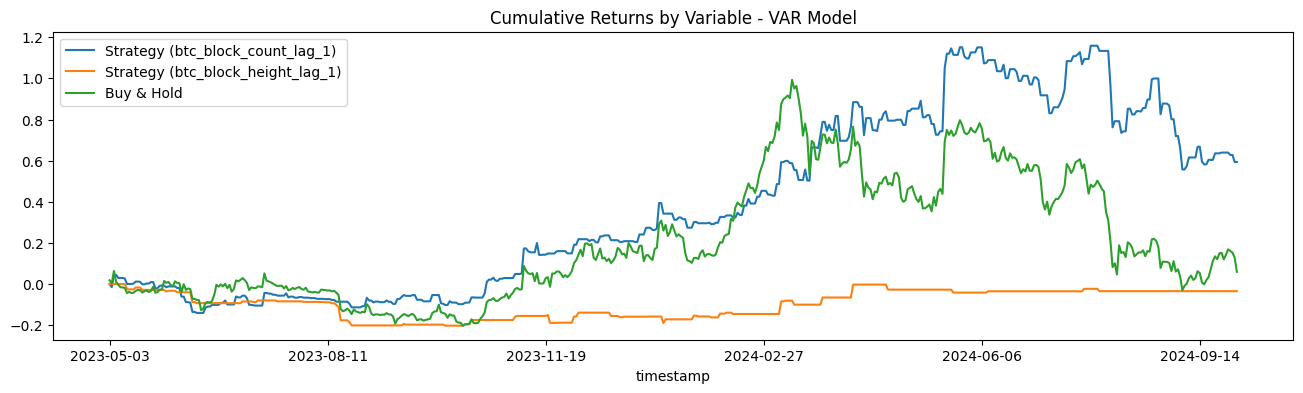


=== VAR Model Performance by Variable ===

Variable: btc_block_count_lag_1
Annualized Return: 60.23%
Volatility: 47.90%
Sharpe Ratio: 1.26
Maximum Drawdown: -27.86%
Number of Trades: 249
Win Rate: 51.41%

Variable: btc_block_height_lag_1
Annualized Return: -14.31%
Volatility: 37.38%
Sharpe Ratio: -0.38
Maximum Drawdown: -18.90%
Number of Trades: 57
Win Rate: 43.86%


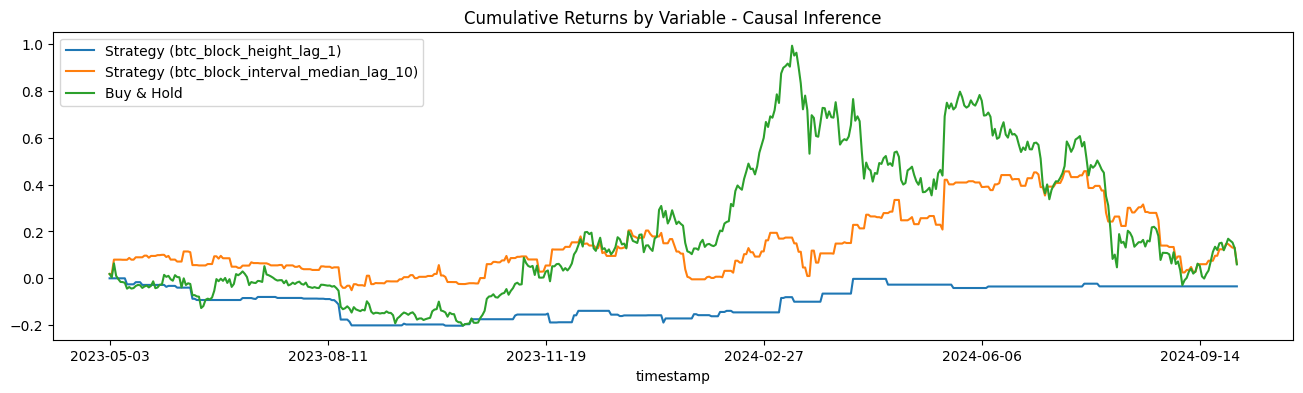


=== Causal Inference Performance by Variable ===

Variable: btc_block_height_lag_1
Annualized Return: -14.31%
Volatility: 37.38%
Sharpe Ratio: -0.38
Maximum Drawdown: -18.90%
Number of Trades: 57
Win Rate: 43.86%

Variable: btc_block_interval_median_lag_10
Annualized Return: 6.80%
Volatility: 44.50%
Sharpe Ratio: 0.15
Maximum Drawdown: -29.66%
Number of Trades: 229
Win Rate: 49.78%


{'Annualized Return': np.float64(0.06796814978925436),
 'Volatility': np.float64(0.4450249981606948),
 'Sharpe Ratio': np.float64(0.15272883561635706),
 'MDD': np.float64(-0.29660816277702307)}

In [426]:
def calculate_performance_metrics(returns, trading_days=252):
    """성과지표 계산 함수"""
    cumulative_returns = (1 + returns).cumprod() - 1
    total_return = cumulative_returns.iloc[-1]
    ann_return = (1 + total_return) ** (trading_days/len(returns)) - 1
    
    std = returns.std() * np.sqrt(trading_days)
    sharpe = ann_return / std if std != 0 else 0
    
    # MDD 계산
    cumulative = (1 + returns).cumprod()
    running_max = cumulative.expanding().max()
    drawdown = (cumulative - running_max) / running_max
    mdd = drawdown.min()
    
    return {
        'Annualized Return': ann_return,
        'Volatility': std,
        'Sharpe Ratio': sharpe,
        'MDD': mdd
    }

def test_model_profitability(dataloader: DataLoader, 
                             significant_vars: list, 
                             model_name: str,
                             asset: str = "eth", 
                             cost=0.0015):
    """각 모델별 수익성 테스트"""
    width, height = 16, 4
    fig, ax = plt.subplots(1, 1, figsize=(width, height))
    
    target = f"{asset}_returns"
    
    # 데이터로더에서 테스트 데이터 가져오기
    df = dataloader.data_test.copy()
    
    # 각 변수별 시그널 및 수익률 계산
    valid_strategies = {}
    for var, coef in significant_vars.items():
        # 시그널 생성
        if coef > 0:
            signal = (df[var] > 0).astype(int)
        else:
            signal = (df[var] < 0).astype(int)
            
        # 거래 횟수가 30번 미만이면 스킵
        if signal.sum() < 30:
            continue
            
        # 개별 변수의 수익률 계산
        strategy_returns = df[target] * signal
        cumulative_returns = (1 + strategy_returns).cumprod() - 1
        
        # 성과지표 계산
        metrics = calculate_performance_metrics(strategy_returns[strategy_returns != 0])
        
        # 유효한 전략 저장
        valid_strategies[var] = {
            'coef': coef,
            'signal': signal,
            'returns': cumulative_returns,
            'sharpe': metrics['Sharpe Ratio']
        }
    
    # 상위 5개 전략만 선택
    if len(valid_strategies) > 5:
        sorted_strategies = dict(sorted(valid_strategies.items(), 
                                     key=lambda x: x[1]['sharpe'], 
                                     reverse=True)[:5])
        valid_strategies = sorted_strategies
        
    # 유효한 전략이 없는 경우
    if not valid_strategies:
        print(f"No valid strategies found for {model_name}")
        return None
        
    # 선택된 전략들의 수익률 그래프 표시
    for var, strategy in valid_strategies.items():
        strategy['returns'].plot(ax=ax, label=f'Strategy ({var})')
    
    # 벤치마크 수익률 추가
    benchmark_returns = (1 + df[target]).cumprod() - 1
    benchmark_returns.plot(ax=ax, label='Buy & Hold')
    
    ax.set_title(f"Cumulative Returns by Variable - {model_name}")
    ax.legend()
    plt.show()
    
    # 각 변수별 성과 지표 출력
    print(f"\n=== {model_name} Performance by Variable ===")
    metrics = {}
    for var, strategy in valid_strategies.items():
        signal = strategy['signal']
        strategy_returns = df[target] * signal
        metrics = calculate_performance_metrics(strategy_returns[strategy_returns != 0])
        trade_days = signal.sum()
        win_rate = (strategy_returns[signal == 1] > 0).mean()
        
        print(f"\nVariable: {var}")
        print(f"Annualized Return: {metrics['Annualized Return']:.2%}")
        print(f"Volatility: {metrics['Volatility']:.2%}")
        print(f"Sharpe Ratio: {metrics['Sharpe Ratio']:.2f}")
        print(f"Maximum Drawdown: {metrics['MDD']:.2%}")
        print(f"Number of Trades: {trade_days}")
        print(f"Win Rate: {win_rate:.2%}")
    
    return metrics

# BTC 전략 테스트
print("=== Bitcoin Trading Strategies ===")
test_model_profitability(dataloader, significant_vars_granger_btc, "Granger Causality", asset='btc')
test_model_profitability(dataloader, significant_vars_VAR_btc, "VAR Model", asset='btc')
test_model_profitability(dataloader, significant_vars_CI_btc, "Causal Inference", asset='btc')

# ETH 전략 테스트
print("\n=== Ethereum Trading Strategies ===")
test_model_profitability(dataloader, significant_vars_granger_eth, "Granger Causality", asset='eth')
test_model_profitability(dataloader, significant_vars_VAR_eth, "VAR Model", asset='eth')
test_model_profitability(dataloader, significant_vars_CI_eth, "Causal Inference", asset='eth')

In [421]:
significant_vars_VAR_btc

{'eth_block_height_lag_3': 0.022301258716786662}

In [406]:
result = granger_btc[(granger_btc['variable'] == 'eth_block_count') & granger_btc['model_lag'].isin([3, 5, 10])].drop_duplicates(subset=['model_lag']).drop('lag', axis=1)
result.reset_index(drop=True)

,variable,model_lag,p_value,test_statistic,coefficient
0,eth_block_count,10,0.006001,19.807468,0.000965
1,eth_block_count,3,0.026697,9.204044,0.001025
2,eth_block_count,5,0.026697,9.204044,0.001025


In [416]:
result = granger_eth[granger_eth['variable'].isin(['eth_block_count']) & granger_eth['model_lag'].isin([3, 5])]
result2 = granger_eth[granger_eth['variable'].isin(['btc_block_count']) & granger_eth['model_lag'].isin([1, 5])]
result3 = granger_eth[granger_eth['variable'].isin(['btc_block_interval_median']) & granger_eth['model_lag'].isin([1])]
result = pd.concat([result, result2, result3])
result.reset_index(drop=True)

,variable,model_lag,lag,p_value,test_statistic,coefficient
0,eth_block_count,5,2,0.038629,6.507494,0.002170
1,eth_block_count,3,2,0.038629,6.507494,0.002170
2,btc_block_count,1,1,0.046669,3.957280,0.002306
3,btc_block_count,5,1,0.046669,3.957280,0.002306
4,btc_block_interval_median,1,1,0.017084,5.687691,0.002296


In [409]:
result = granger_eth[granger_eth['variable'].isin(['eth_block_count', 'btc_block_count', 'btc_block_interval_median']) & granger_eth['model_lag'].isin([1, 3, 5, 10])].drop_duplicates(subset=['model_lag']).drop('lag', axis=1)
result.reset_index(drop=True)

,variable,model_lag,p_value,test_statistic,coefficient
0,eth_block_count,10,0.014202,17.544676,0.001915
1,btc_block_interval_median,1,0.017084,5.687691,0.002296
2,btc_block_interval_median,5,0.017084,5.687691,0.002296
3,btc_block_interval_median,3,0.017084,5.687691,0.002296


In [417]:
var_eth

""


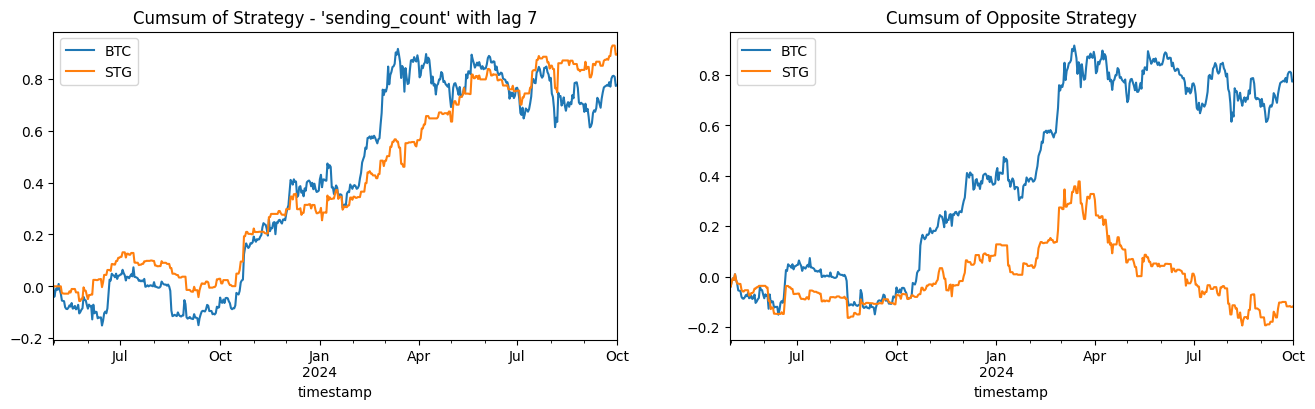

Entire Trading days : 521
Trading days for left: 245                                                                | Trading days for right: 276
Average Return for left: 0.0036                                                           | Average Return for right: -0.0004
Cummulative Sum Return for left: 0.8938                                                   | Cummulative Sum Return for right: -0.1174
Sharpe Ratio for left: 0.1491                                                             | Sharpe Ratio for right: -0.0171


In [50]:
test_profitability(test_btc, "sending_count")

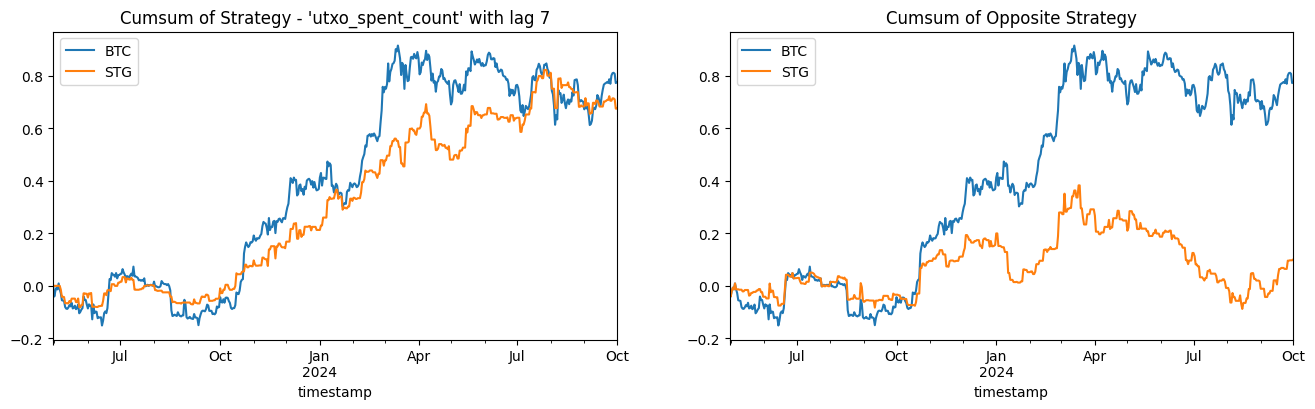

Entire Trading days : 521
Trading days for left: 262                                                                | Trading days for right: 259
Average Return for left: 0.0026                                                           | Average Return for right: 0.0004
Cummulative Sum Return for left: 0.6756                                                   | Cummulative Sum Return for right: 0.1007
Sharpe Ratio for left: 0.1055                                                             | Sharpe Ratio for right: 0.0155


In [13]:
test_profitability(test_btc, "utxo_spent_count")

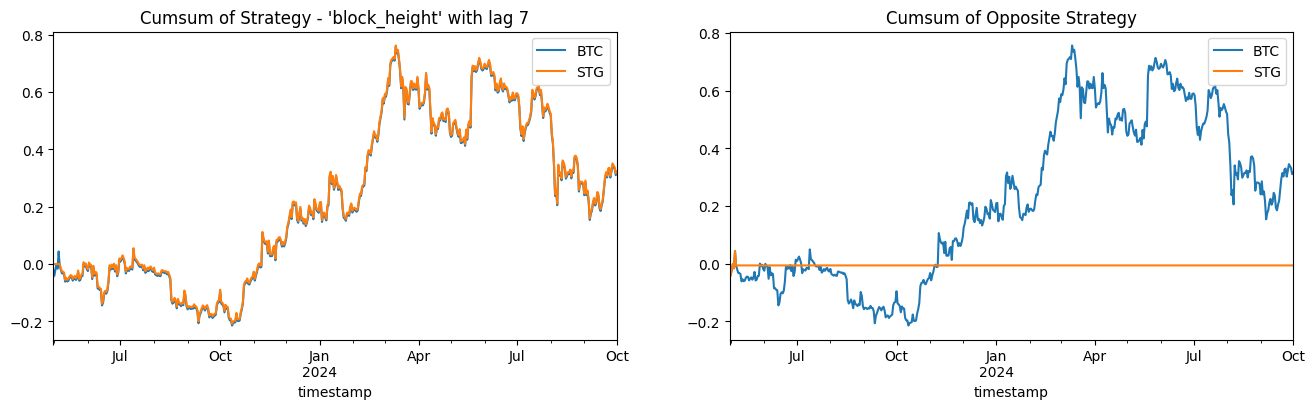

Entire Trading days : 521
Trading days for left: 514                                                                | Trading days for right: 7
Average Return for left: 0.0006                                                           | Average Return for right: -0.0009
Cummulative Sum Return for left: 0.3227                                                   | Cummulative Sum Return for right: -0.0060
Sharpe Ratio for left: 0.0221                                                             | Sharpe Ratio for right: -0.0237


In [182]:
test_profitability(test_eth, "block_height")

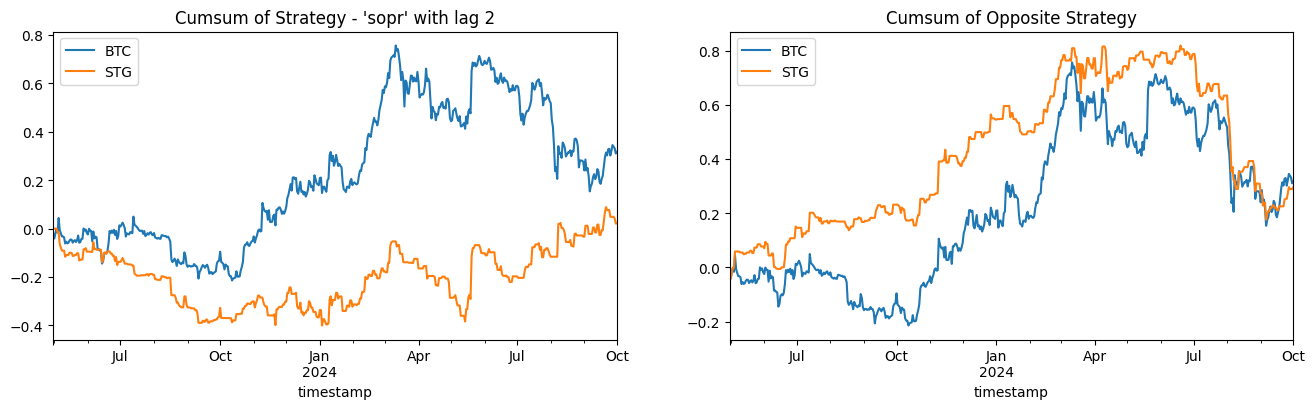

Entire Trading days : 521
Trading days for left: 262                                                                | Trading days for right: 259
Average Return for left: 0.0001                                                           | Average Return for right: 0.0011
Cummulative Sum Return for left: 0.0210                                                   | Cummulative Sum Return for right: 0.2957
Sharpe Ratio for left: 0.0029                                                             | Sharpe Ratio for right: 0.0390


In [14]:
test_profitability(test_eth, "sopr", lag=2)

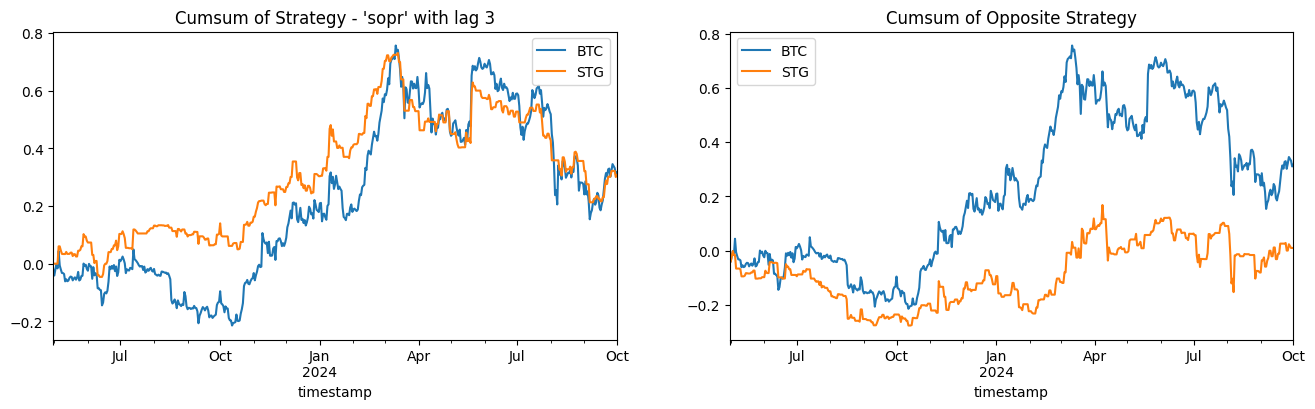

Entire Trading days : 521
Trading days for left: 262                                                                | Trading days for right: 259
Average Return for left: 0.0012                                                           | Average Return for right: 0.0000
Cummulative Sum Return for left: 0.3068                                                   | Cummulative Sum Return for right: 0.0099
Sharpe Ratio for left: 0.0414                                                             | Sharpe Ratio for right: 0.0013


In [15]:
test_profitability(test_eth, "sopr", lag=3)

### Using VECM

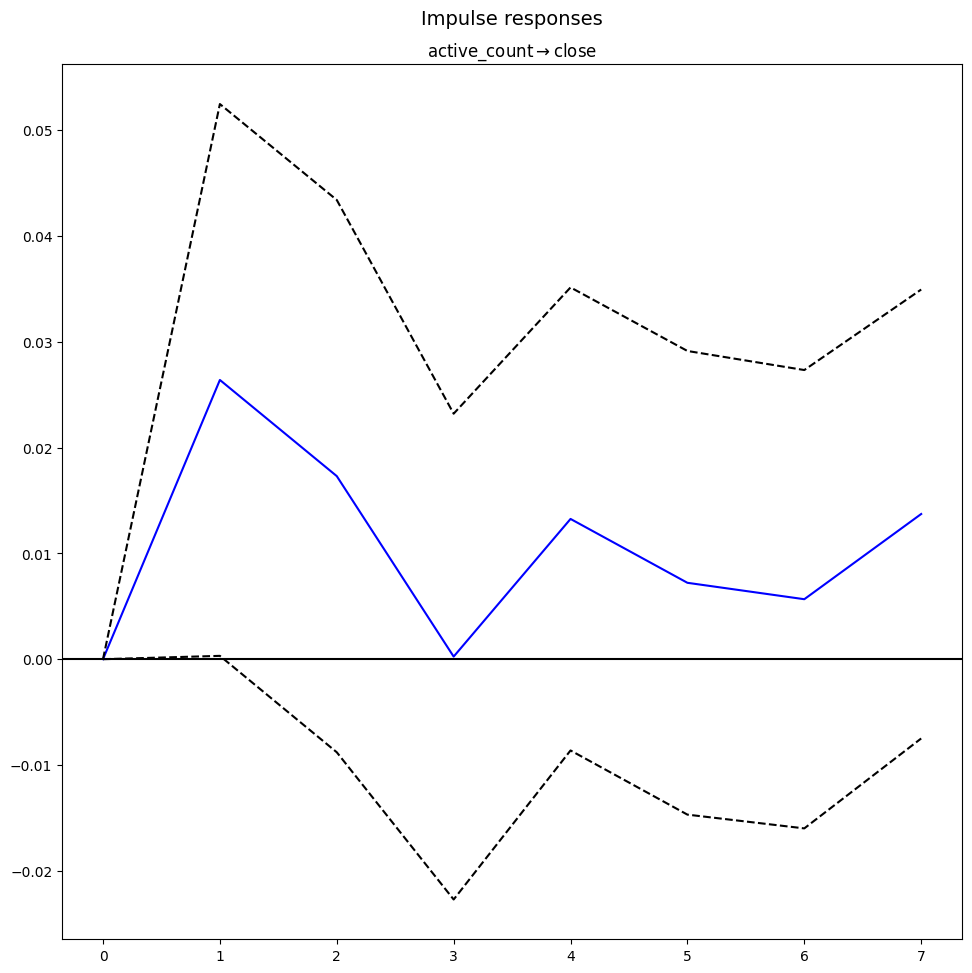

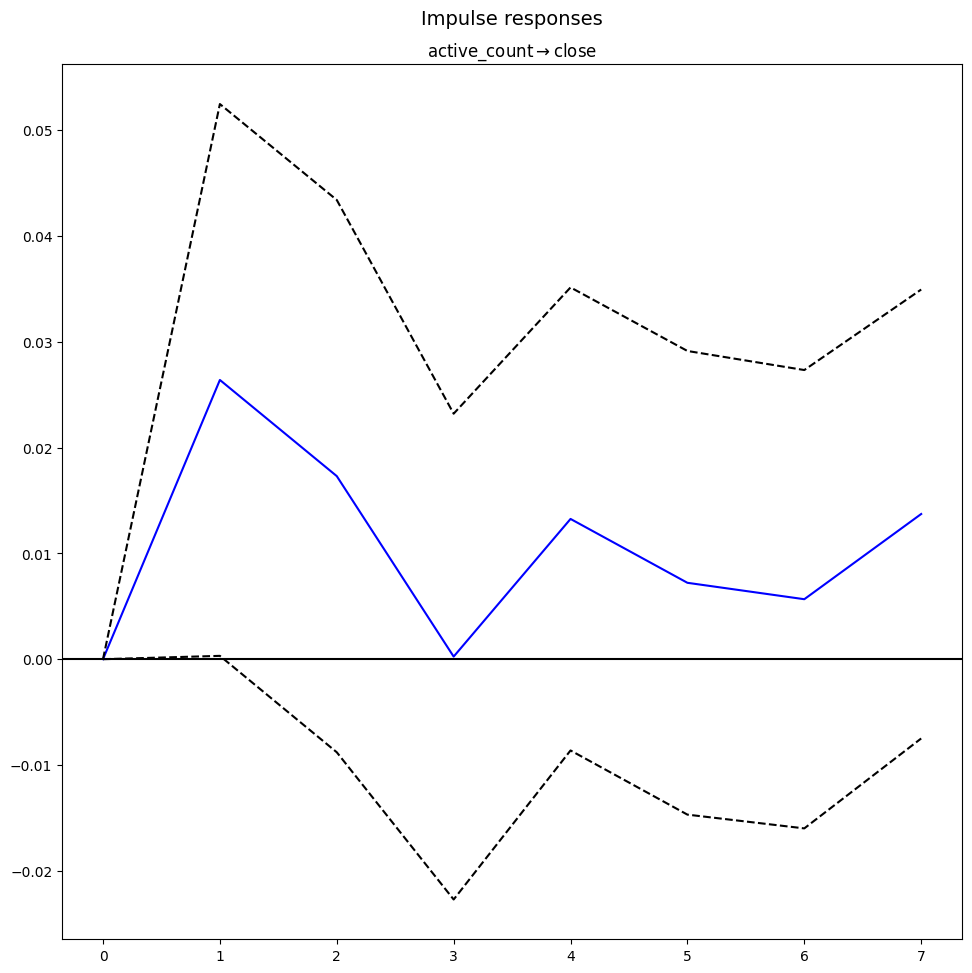

In [39]:
from statsmodels.tsa.api import VAR

coint_result = coint_johansen(train_btc[['close', 'active_count']], det_order=0, k_ar_diff=7)
rank = sum(coint_result.lr1 > coint_result.cvt[:, 1])  # 5% critical value 기준

model = VECM(train_btc[['close', 'active_count']], k_ar_diff=7, coint_rank=rank)
fitted_model = model.fit()
irf = fitted_model.irf(7)  # 10기간 동안의 반응

irf.plot(impulse='active_count', response='close')  # var1이 var2에 미치는 영향

In [34]:
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen
from statsmodels.tsa.api import VAR
import numpy as np

def test_vecm(df, maxlag=10):
    vecm_results = []
    
    for col in df.columns:
        if col == "close":
            continue
        
        # 가장 낮은 AIC 선택
        model = VAR(df[['close', col]])
        lag_order = model.select_order(maxlags=10)
        best_lag = lag_order.aic
        
        # Johansen test to check for cointegration
        coint_result = coint_johansen(df[['close', col]], det_order=0, k_ar_diff=maxlag)
        rank = sum(coint_result.lr1 > coint_result.cvt[:, 1])  # 5% critical value 기준
        
        if rank > 0:  # 공적분 벡터가 존재하는 경우
            # VECM 모델 피팅
            model = VECM(df[['close', col]], k_ar_diff=best_lag, coint_rank=rank)
            fitted_model = model.fit()
        
        if fitted_model is not None:
            # 각 시차별로 유의미한 변수 확인
            print(fitted_model.__dir__())
            for i in range(fitted_model.k_ar_diff):

                if fitted_model.pvalues[i].min() < 0.01:  # 통계적으로 유의미한 경우
                    print(f"{col} : lag {i+1} is statistically significant")
                    print(f"coef: {fitted_model.beta[1][0]}")
                    
            vecm_results.append(fitted_model)
    
    return vecm_results

# 테스트용
space = 30
MAXLAG = 10

print("-"*space + "BTC" + "-"*space)
vecm_btc = test_vecm(train_btc, MAXLAG)
print("-"*space + "ETH" + "-"*space)
vecm_eth = test_vecm(train_eth, MAXLAG)


------------------------------BTC------------------------------
['model', 'y_all', 'exog', 'exog_coint', 'names', 'dates', 'neqs', 'k_ar', 'deterministic', 'seasons', 'first_season', 'coint_rank', 'alpha', 'beta', 'det_coef_coint', 'gamma', 'det_coef', 'const_coint', 'lin_trend_coint', 'exog_coint_coefs', 'const', 'seasonal', 'lin_trend', 'exog_coefs', 'sigma_u', '_delta_y_1_T', '_y_lag1', '_delta_x', 'nobs', '__module__', '__doc__', '__init__', 'llf', '_cov_sigma', 'cov_params_default', 'cov_params_wo_det', 'stderr_params', 'stderr_coint', 'stderr_alpha', 'stderr_beta', 'stderr_det_coef_coint', 'stderr_gamma', 'stderr_det_coef', 'tvalues_alpha', 'tvalues_beta', 'tvalues_det_coef_coint', 'tvalues_gamma', 'tvalues_det_coef', 'pvalues_alpha', 'pvalues_beta', 'pvalues_det_coef_coint', 'pvalues_gamma', 'pvalues_det_coef', '_make_conf_int', 'conf_int_alpha', 'conf_int_beta', 'conf_int_det_coef_coint', 'conf_int_gamma', 'conf_int_det_coef', 'var_rep', 'cov_var_repr', 'ma_rep', '_chol_sigma_u

AttributeError: 'VECMResults' object has no attribute 'k_ar_diff'

In [51]:
import numpy as np
import pandas as pd
from dtaidistance import dtw

# 예제 데이터 생성
np.random.seed(0)
n = 100
time_series_a = np.random.randn(n).cumsum()  # 예시 시계열 A
time_series_b = np.random.randn(n).cumsum()  # 예시 시계열 B

# DataFrame으로 변환
data = pd.DataFrame({'A': time_series_a, 'B': time_series_b})

# DTW 거리 계산
distance, path = dtw.warping_path(data['A'], data['B'])

# 최적의 정렬된 경로 출력
print(f"DTW 거리: {distance}")
print(f"Optimal path: {path}")

# 시차 계산
lag = path[-1][1] - path[-1][0]  # 마지막 포인트에서의 시차
print(f"Lead-lag relationship (lag): {lag}")


ModuleNotFoundError: No module named 'dtaidistance'